# Complex-Time Anharmonic Propagator — corrected multi-thimble MU

This notebook loops $\lambda=1,2,\dots,8$ at $N=16$ and compares the physical-cycle
ML propagator against the **lattice FFT** values from
`Re__Complex_Time_Code_/py_scripts_extracted/exact_check_Loop.py`
(the same discretised integral).  Continuum spectral numbers are shown only as a
discretisation check; they are not the ML target.

The old calculation learned only the thimble through the zero saddle.  For the hard
quartic oscillator there is also a lowest-action nonzero zero-endpoint saddle and its
parity partner.  With every tangent given the canonical `det(V)=+1` orientation, the
physical real integration cycle decomposes as

$$K_{\rm physical}=K_{0}+K_{+}+K_{-}=K_{0}+2K_{\rm bounce}.$$

Each contribution is learned independently by a saddle-anchored rank-16 neural contour.
The implementation also incorporates the definite corrections from
`Re__Complex_Time_Code_`:

- `complex128` action, Jacobian and weights;
- the correct $A^{-1}C$ low-rank determinant formula for `x = z @ A.T`;
- a full finite-difference Jacobian preflight;
- comparison to the deterministic **same-$N$** anharmonic reference, not the $\lambda=0$
  Mehler kernel;
- stable `log|W|` plus circular-phase training, avoiding an angle branch cut.

Default settings (`1000` epochs per saddle, `80,000` MC samples) reproduce the $N=16$
reference in about 1–2 minutes on this CPU.

In [1]:
from __future__ import annotations

import csv
import json
import math
import os
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg
import torch
import torch.nn as nn
from scipy.optimize import root

%matplotlib inline

torch.set_default_dtype(torch.float64)

# Physics: same N=16 complex-time lattice as exact_check_Loop.py
N = 16
D = N - 1
T = 1.0
ETA = 0.05
MASS = 1.0
OMEGA = 1.0
LAMBDA_LIST = list(range(1, 9))  # lambda = 1, 2, ..., 8
LAMBDA = float(LAMBDA_LIST[0])   # current coupling; updated inside the loop
A_C = (T - 1j * ETA) / N
X_I = X_F = 0.0
EXACT_CSV = Path("Re__Complex_Time_Code_") / "py_scripts_extracted" / "exact_check_Loop_lambda1to8.csv" 

# Fastest configuration tested to remain statistically meaningful.
RANK = 16
EPOCHS = 1_000
BATCH = 512
LEARNING_RATE = 1.0e-3
N_MC = 80_000
MC_CHUNK = 5_000
SEED = 52
LOG_EVERY = 250

# Set True only for a syntax check; its numbers are not physics results.
QUICK_TEST = False
if QUICK_TEST:
    EPOCHS, BATCH, N_MC, MC_CHUNK, LOG_EVERY = 5, 32, 1_000, 500, 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
loop_dir = Path("runs") / f"{stamp}_MU_Loop_lambda1to8_N{N}"
loop_dir.mkdir(parents=True, exist_ok=True)
run_dir = loop_dir  # overwritten per lambda inside the loop

print(f"device={DEVICE}; dtype=float64/complex128")
print(f"N={N}, D={D}, T_c={T}-{ETA}i, lambda_list={LAMBDA_LIST}")
print(f"rank={RANK}, epochs={EPOCHS} per saddle, batch={BATCH}, N_mc={N_MC}")
print(f"exact lattice CSV: {EXACT_CSV.resolve()}")
print(f"loop directory: {loop_dir.resolve()}")

device=cpu; dtype=float64/complex128
N=16, D=15, T_c=1.0-0.05i, lambda_list=[1, 2, 3, 4, 5, 6, 7, 8]
rank=16, epochs=1000 per saddle, batch=512, N_mc=80000
exact lattice CSV: C:\xampp1\Quantum\Re__Complex_Time_Code_\py_scripts_extracted\exact_check_Loop_lambda1to8.csv
loop directory: C:\xampp1\Quantum\runs\20260916_103537_MU_Loop_lambda1to8_N16


## 1. Lattice action and stationary points

For zero endpoints, the $D=N-1$ complex interior coordinates have action

$$S[x]=\frac{m}{2a_c}\sum_{k=0}^{N-1}(x_{k+1}-x_k)^2
-\frac{a_cm\omega^2}{2}\sum_{k=1}^{N-1}x_k^2
-\frac{a_c\lambda}{4}\sum_{k=1}^{N-1}x_k^4,$$

with $a_c=(T-i\eta)/N$ and weight $e^{iS}$.  Unlike the harmonic oscillator, the hard
quartic oscillator has nonzero zero-to-zero solutions even when $T<\pi/\omega$: increasing
amplitude raises its frequency.  The previous notebook incorrectly retained only $x=0$.

In [2]:
def action_np(x: np.ndarray) -> complex:
    """Discretised complex-time action for one path."""
    padded = np.r_[0.0 + 0.0j, x, 0.0 + 0.0j]
    dx = np.diff(padded)
    return (
        MASS / (2.0 * A_C) * np.sum(dx**2)
        - A_C * MASS * OMEGA**2 / 2.0 * np.sum(x**2)
        - A_C * LAMBDA / 4.0 * np.sum(x**4)
    )


def gradient_np(x: np.ndarray) -> np.ndarray:
    """Holomorphic gradient dS/dx at the interior lattice sites."""
    padded = np.r_[0.0 + 0.0j, x, 0.0 + 0.0j]
    return (
        (MASS / A_C) * (2.0 * x - padded[:-2] - padded[2:])
        - A_C * MASS * OMEGA**2 * x
        - A_C * LAMBDA * x**3
    )


def hessian_np(x: np.ndarray) -> np.ndarray:
    """Complex-symmetric Hessian d^2S/dx_j dx_k at a saddle."""
    hessian = np.zeros((D, D), dtype=np.complex128)
    np.fill_diagonal(
        hessian,
        2.0 * MASS / A_C
        - A_C * MASS * OMEGA**2
        - 3.0 * A_C * LAMBDA * x**2,
    )
    np.fill_diagonal(hessian[1:], -MASS / A_C)
    np.fill_diagonal(hessian[:, 1:], -MASS / A_C)
    return hessian


def packed_gradient(y: np.ndarray) -> np.ndarray:
    x = y[:D] + 1j * y[D:]
    grad = gradient_np(x)
    return np.r_[grad.real, grad.imag]


def action_torch(x: torch.Tensor) -> torch.Tensor:
    """Batch action accumulated entirely in complex128."""
    x = x.to(torch.complex128)
    zero = torch.zeros((x.shape[0], 1), dtype=torch.complex128, device=x.device)
    padded = torch.cat((zero, x, zero), dim=1)
    dx = padded[:, 1:] - padded[:, :-1]
    a = torch.as_tensor(A_C, dtype=torch.complex128, device=x.device)
    return (
        MASS / (2.0 * a) * torch.sum(dx**2, dim=1)
        - a * MASS * OMEGA**2 / 2.0 * torch.sum(x**2, dim=1)
        - a * LAMBDA / 4.0 * torch.sum(x**4, dim=1)
    )

## 2. Locate the missing bounce and construct local thimble tangents

The first nonzero saddle is found from sine-wave initial guesses and refined against the
full complex lattice equations.  Its parity partner $-x_{\rm b}$ has exactly the same action
and Hessian because the potential is even.

At each saddle, a complex-orthogonal eigendecomposition builds $A_\sigma$ satisfying

$$A_\sigma^T H_\sigma A_\sigma=iI,$$

so $x=x_\sigma+A_\sigma z$ starts on the exact local steepest-descent tangent.  The saddle and
this linear map remain fixed during training, preventing either network from drifting into
the zero saddle or flipping orientation.

In [3]:
def first_bounce() -> np.ndarray:
    """Find the lowest-action nonzero zero-endpoint saddle.

    A hard quartic oscillator has amplitude-dependent frequency, so this solution exists
    even though T < pi/omega.  Several amplitudes are tried to avoid accepting x=0.
    """
    sites = np.arange(1, N)
    shape = np.sin(np.pi * sites / N)
    candidates = []
    for amplitude in np.linspace(0.5, 10.0, 20):
        guess = np.r_[amplitude * shape, np.zeros(D)]
        solved = root(packed_gradient, guess, method="lm", options={"maxiter": 5_000})
        x = solved.x[:D] + 1j * solved.x[D:]
        residual = np.max(np.abs(gradient_np(x)))
        if residual < 1e-8 and np.max(np.abs(x)) > 1e-3:
            if not any(np.max(np.abs(x - old)) < 1e-6 for old in candidates):
                candidates.append(x)
    if not candidates:
        raise RuntimeError("Could not find the first nonzero saddle")
    return min(candidates, key=lambda x: abs(action_np(x)))


def tangent_map(hessian: np.ndarray) -> np.ndarray:
    """Return canonically oriented A with A.T @ H @ A = iI."""
    values, vectors = np.linalg.eig(hessian)
    for k in range(D):
        vectors[:, k] /= np.sqrt(vectors[:, k].T @ vectors[:, k])

    # Complex orthogonality implies det(V)=+/-1.  Fix +1 so every saddle uses
    # the same orientation inherited from the real coordinate basis; otherwise
    # a LAPACK eigenvector sign arbitrarily changes K_sigma -> -K_sigma.
    if np.linalg.det(vectors).real < 0.0:
        vectors[:, 0] *= -1.0

    orthogonal_error = np.max(np.abs(vectors.T @ vectors - np.eye(D)))
    orientation_error = abs(np.linalg.det(vectors) - 1.0)
    tangent = vectors @ np.diag(np.sqrt(1j / values))
    residual = np.max(np.abs(tangent.T @ hessian @ tangent - 1j * np.eye(D)))
    if orthogonal_error > 1e-8 or orientation_error > 1e-8 or residual > 1e-8:
        raise RuntimeError(
            "Bad saddle tangent: "
            f"orthogonal={orthogonal_error}, orientation={orientation_error}, "
            f"congruence={residual}"
        )
    return tangent


def fixed_n_reference(basis_size: int = 300) -> complex:
    """Independent deterministic evaluation of this exact N-slice path integral."""
    nb = int(basis_size)
    lowering = np.zeros((nb, nb), dtype=np.float64)
    idx = np.arange(1, nb)
    lowering[idx - 1, idx] = np.sqrt(idx)
    x_op = (lowering + lowering.T) / np.sqrt(2.0)
    p_op = (lowering - lowering.T) / (1j * np.sqrt(2.0))
    x2 = x_op @ x_op

    kinetic = p_op @ p_op / (2.0 * MASS)
    ep, up = scipy.linalg.eigh(kinetic)
    free_step = (up * np.exp(-1j * A_C * ep)) @ up.conj().T

    potential = MASS * OMEGA**2 * x2 / 2.0 + LAMBDA * (x2 @ x2) / 4.0
    ev, uv = scipy.linalg.eigh(potential)
    potential_step = (uv * np.exp(-1j * A_C * ev)) @ uv.conj().T

    position_zero = np.zeros(nb, dtype=np.float64)
    for n in range(0, nb, 2):
        q = n // 2
        position_zero[n] = (-1.0)**q * math.exp(
            0.5 * math.lgamma(2 * q + 1) - q * math.log(2.0)
            - math.lgamma(q + 1) - 0.25 * math.log(np.pi)
        )

    evolution = free_step.copy()
    for _ in range(N - 1):
        evolution = evolution @ potential_step @ free_step
    return complex(position_zero @ evolution @ position_zero)


def gaussian_saddle_estimate(saddle: np.ndarray) -> complex:
    """Quadratic saddle estimate; used only as a decomposition diagnostic."""
    hessian = hessian_np(saddle)
    norm = (MASS / (2.0 * np.pi * 1j * A_C)) ** (N / 2)
    return complex(
        norm * np.exp(1j * action_np(saddle))
        * (2.0 * np.pi * 1j) ** (D / 2) / np.sqrt(np.linalg.det(hessian))
    )

## 3. Saddle-anchored neural contour

For each saddle $x_\sigma$ the learned map is

$$x(z)=x_\sigma+A_\sigma z+C\tanh\!\left(W_2\tanh(W_1z)\right).$$

There are no neural biases, so $g(0)=0$ and the contour always passes through its assigned
saddle.  $A_\sigma$ and $x_\sigma$ are buffers rather than trainable parameters.  Only the
rank-16 nonlinear correction learns.

The full Jacobian is

$$J=A_\sigma+C D_2W_2D_1W_1.$$

For `x = z @ A.T`, Sylvester's identity requires **`solve(A, C)`**.  The old notebook used
`solve(A.T, C)`, i.e. $A^{-T}C$, which is the transpose bug identified in
`Re__Complex_Time_Code_/note_for_tom.pdf`.

In [4]:
class SaddleFlow(nn.Module):
    """Fixed saddle/tangent plus a saddle-anchored low-rank correction."""

    def __init__(self, saddle: np.ndarray, tangent: np.ndarray, seed: int):
        super().__init__()
        torch.manual_seed(seed)
        self.register_buffer(
            "saddle", torch.tensor(saddle, dtype=torch.complex128, device=DEVICE)
        )
        self.register_buffer(
            "A", torch.tensor(tangent, dtype=torch.complex128, device=DEVICE)
        )
        self.W1 = nn.Parameter(torch.randn(RANK, D, device=DEVICE) / math.sqrt(D))
        qmat, _ = torch.linalg.qr(torch.randn(RANK, RANK, device=DEVICE))
        self.W2 = nn.Parameter(qmat)
        # Tiny rather than exactly zero so every layer receives a gradient on step one.
        self.C_real = nn.Parameter(1e-5 * torch.randn(D, RANK, device=DEVICE))
        self.C_imag = nn.Parameter(1e-5 * torch.randn(D, RANK, device=DEVICE))

    def C(self) -> torch.Tensor:
        return self.C_real.to(torch.complex128) + 1j * self.C_imag.to(torch.complex128)

    def forward(self, z: torch.Tensor, return_cache: bool = False):
        z = z.to(dtype=torch.float64, device=DEVICE)
        a1 = torch.tanh(z @ self.W1.T)
        a2 = torch.tanh(a1 @ self.W2.T)
        x = (
            z.to(torch.complex128) @ self.A.T
            + self.saddle
            + a2.to(torch.complex128) @ self.C().T
        )
        return (x, (a1, a2)) if return_cache else x

    def full_jacobian(self, a1: torch.Tensor, a2: torch.Tensor) -> torch.Tensor:
        """Exact batch Jacobian A + C D2 W2 D1 W1, including all cross terms."""
        d1 = 1.0 - a1**2
        d2 = 1.0 - a2**2
        h1 = d1.unsqueeze(-1) * self.W1.unsqueeze(0)
        h2 = torch.matmul(self.W2.unsqueeze(0), h1)
        dh_dz = d2.unsqueeze(-1) * h2
        correction = torch.matmul(self.C().unsqueeze(0), dh_dz.to(torch.complex128))
        return self.A.unsqueeze(0) + correction

    def determinant_parts(self, a1: torch.Tensor, a2: torch.Tensor):
        """Return log|det J| and det(J)/|det(J)| via the corrected low-rank formula."""
        sign_a, logabs_a = torch.linalg.slogdet(self.A)
        # Correct for forward x = z @ A.T.  This is A^{-1}C, not A^{-T}C.
        k_mat = self.W1.to(torch.complex128) @ torch.linalg.solve(self.A, self.C())
        d1 = (1.0 - a1**2).to(torch.complex128)
        d2 = (1.0 - a2**2).to(torch.complex128)
        m1 = d1.unsqueeze(-1) * k_mat.unsqueeze(0)
        m2 = torch.matmul(self.W2.to(torch.complex128).unsqueeze(0), m1)
        correction = (
            torch.eye(RANK, dtype=torch.complex128, device=DEVICE).unsqueeze(0)
            + d2.unsqueeze(-1) * m2
        )
        sign_c, logabs_c = torch.linalg.slogdet(correction)
        return logabs_a + logabs_c, sign_a * sign_c

## 4. Preflight checks

Before training, the notebook verifies:

1. the bounce residual $\|\partial S/\partial x\|_\infty$;
2. parity: $S[x_b]=S[-x_b]$ and $H[x_b]=H[-x_b]$;
3. $A_\sigma^T H_\sigma A_\sigma=iI$;
4. the analytic full Jacobian against central finite differences;
5. the corrected low-rank determinant against `det(full_jacobian)`.

The quadratic saddle estimates provide an independent scale check.  Already at Gaussian
order, subtracting the bounce pair shifts the zero-saddle answer in precisely the direction
required by the deterministic reference.

In [5]:
def validate_saddles_and_jacobian(trivial: np.ndarray, bounce: np.ndarray) -> None:
    residual = np.max(np.abs(gradient_np(bounce)))
    parity_action = abs(action_np(bounce) - action_np(-bounce))
    parity_hessian = np.max(np.abs(hessian_np(bounce) - hessian_np(-bounce)))
    if residual > 1e-8 or parity_action > 1e-10 or parity_hessian > 1e-10:
        raise RuntimeError("Saddle or parity preflight failed")

    tangent = tangent_map(hessian_np(bounce))
    model = SaddleFlow(bounce, tangent, SEED + 999)
    # Make the nonlinear correction large enough that the check tests it, not only A.
    with torch.no_grad():
        model.C_real.normal_(std=0.03)
        model.C_imag.normal_(std=0.03)

    z = torch.randn(3, D, dtype=torch.float64, device=DEVICE)
    x, (a1, a2) = model(z, return_cache=True)
    jacobian = model.full_jacobian(a1, a2)
    eps = 1e-6
    jacobian_fd = torch.empty_like(jacobian)
    with torch.no_grad():
        for k in range(D):
            dz = torch.zeros_like(z)
            dz[:, k] = eps
            jacobian_fd[:, :, k] = (model(z + dz) - model(z - dz)) / (2.0 * eps)
    fd_error = float(torch.max(torch.abs(jacobian - jacobian_fd)).cpu())

    logabs, sign = model.determinant_parts(a1, a2)
    det_low_rank = torch.exp(logabs) * sign
    det_full = torch.linalg.det(jacobian)
    determinant_error = float(torch.max(torch.abs(det_low_rank - det_full)).cpu())
    determinant_relative = determinant_error / max(
        float(torch.max(torch.abs(det_full)).cpu()), 1e-300
    )

    print(f"bounce residual              : {residual:.3e}")
    print(f"parity action/Hessian errors : {parity_action:.3e}, {parity_hessian:.3e}")
    print(f"full Jacobian FD error       : {fd_error:.3e}")
    print(f"low-rank determinant rel err : {determinant_relative:.3e}")
    if fd_error > 3e-7 or determinant_relative > 3e-8:
        raise RuntimeError("Corrected Jacobian preflight failed")
    print("All saddle and Jacobian preflight checks PASSED")

## 5. Branch-safe training and complex importance weights

For standard-normal $z$, write the weight without taking a complex logarithm:

$$\log|W|=-\operatorname{Im}S+\log|\det J|-\log P(z),\qquad
u_W=e^{i\operatorname{Re}S}\frac{\det J}{|\det J|}.$$

The objective is

$$\operatorname{Var}[\log|W|]+1-|\langle\nu_W\rangle|^2.$$

The second term is circular phase variance; unlike `Var(Im(log W))`, it has no artificial
branch cut at $\pm\pi$.  Estimation retains the required
$W=e^{iS}\det J/P$ and the original complex-time normalization.  Five independent MC
blocks expose sampling instability.

In [6]:
LOG_2PI = math.log(2.0 * math.pi)


def weight_parts(model: SaddleFlow, z: torch.Tensor):
    """Branch-safe representation of exp(iS) det(J) / P(z)."""
    x, (a1, a2) = model(z, return_cache=True)
    action = action_torch(x)
    logabs_j, sign_j = model.determinant_parts(a1, a2)
    log_p = -0.5 * torch.sum(z**2, dim=1) - 0.5 * D * LOG_2PI
    logabs_w = -action.imag + logabs_j - log_p
    phase_w = torch.exp(1j * action.real) * sign_j
    return logabs_w, phase_w


def train_thimble(label: str, saddle: np.ndarray, seed: int):
    tangent = tangent_map(hessian_np(saddle))
    model = SaddleFlow(saddle, tangent, seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS, eta_min=LEARNING_RATE * 0.05
    )
    history = {"total": [], "logmag": [], "phase": []}
    started = time.time()

    for epoch in range(EPOCHS):
        optimizer.zero_grad(set_to_none=True)
        z = torch.randn(BATCH, D, dtype=torch.float64, device=DEVICE)
        logabs_w, phase_w = weight_parts(model, z)
        logmag_variance = torch.var(logabs_w, unbiased=False)
        circular_phase = 1.0 - torch.abs(torch.mean(phase_w))**2
        loss = logmag_variance + circular_phase
        if not torch.isfinite(loss):
            raise FloatingPointError(f"{label}: nonfinite loss at epoch {epoch + 1}")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        scheduler.step()

        history["total"].append(float(loss.detach().cpu()))
        history["logmag"].append(float(logmag_variance.detach().cpu()))
        history["phase"].append(float(circular_phase.detach().cpu()))
        if epoch == 0 or (epoch + 1) % LOG_EVERY == 0 or epoch + 1 == EPOCHS:
            print(
                f"{label:8s} epoch {epoch+1:4d}/{EPOCHS}: "
                f"loss={history['total'][-1]:.3e}, "
                f"logmag={history['logmag'][-1]:.3e}, "
                f"phase={history['phase'][-1]:.3e}, "
                f"elapsed={time.time()-started:.0f}s",
                flush=True,
            )
    return model, history, time.time() - started


def estimate_thimble(model: SaddleFlow, seed: int):
    """Chunked complex128 MC estimate with five independent stability blocks."""
    torch.manual_seed(seed + 100_000)
    logs, phases = [], []
    remaining = N_MC
    model.eval()
    while remaining:
        count = min(MC_CHUNK, remaining)
        z = torch.randn(count, D, dtype=torch.float64, device=DEVICE)
        with torch.no_grad():
            logabs, phase = weight_parts(model, z)
        logs.append(logabs.cpu())
        phases.append(phase.cpu())
        remaining -= count

    logabs = torch.cat(logs)
    phase = torch.cat(phases)
    shift = torch.max(logabs)
    shifted = torch.exp(logabs - shift) * phase
    norm = (MASS / (2.0 * np.pi * 1j * A_C)) ** (N / 2)
    scale = norm * math.exp(float(shift))
    estimate = complex(scale * torch.mean(shifted).numpy())

    centered = shifted - torch.mean(shifted)
    stderr = abs(scale) * math.sqrt(float(torch.mean(torch.abs(centered)**2)) / N_MC)
    ess = float(
        torch.abs(torch.mean(shifted))**2 / torch.mean(torch.abs(shifted)**2)
    )
    blocks = [
        complex(scale * torch.mean(block).numpy())
        for block in torch.tensor_split(shifted, 5)
    ]
    block_scatter = float(np.std(np.asarray(blocks, dtype=np.complex128)))
    return estimate, stderr, ess, block_scatter, blocks

## 6. Exact lattice targets for $\lambda=1\ldots 8$

Load the FFT lattice values produced by `exact_check_Loop.py`.  That is the
correct comparison for this notebook: same $N=16$ discretised path integral.
The continuum column is kept in the table only to show discretisation error.

In [7]:
exact_rows = {}
with EXACT_CSV.open("r", encoding="utf-8") as handle:
    for row in csv.DictReader(handle):
        lam = float(row["lambda"])
        exact_rows[lam] = {
            "lattice": complex(float(row["lattice_K_re"]), float(row["lattice_K_im"])),
            "continuum": complex(float(row["continuum_K_re"]), float(row["continuum_K_im"])),
        }

print(f"Loaded {len(exact_rows)} exact lattice/continuum rows from {EXACT_CSV}")
print(f"{'lam':>6s}  {'lattice K':>32s}  {'continuum K':>32s}")
for lam in LAMBDA_LIST:
    if lam not in exact_rows:
        raise RuntimeError(f"lambda={lam} missing from {EXACT_CSV}")
    print(f"{lam:6.1f}  {exact_rows[lam]['lattice']:+.10f}  {exact_rows[lam]['continuum']:+.10f}")


def run_one_lambda(lam: float):
    """Train both thimbles at one lambda and compare to the lattice FFT target."""
    global LAMBDA, run_dir
    LAMBDA = float(lam)
    run_dir = loop_dir / f"lambda{LAMBDA:g}"
    run_dir.mkdir(parents=True, exist_ok=True)

    trivial_saddle = np.zeros(D, dtype=np.complex128)
    bounce_saddle = first_bounce()
    lattice_ref = exact_rows[lam]["lattice"]
    continuum_ref = exact_rows[lam]["continuum"]
    validate_saddles_and_jacobian(trivial_saddle, bounce_saddle)

    trained = {}
    for offset, (label, saddle) in enumerate(
        (("trivial", trivial_saddle), ("bounce", bounce_saddle))
    ):
        print("\n" + "=" * 84)
        print(f"Training {label} thimble at lambda={LAMBDA}")
        print("=" * 84, flush=True)
        model, history, seconds = train_thimble(label, saddle, SEED + offset)
        estimate, stderr, ess, block_scatter, blocks = estimate_thimble(model, SEED + offset)
        trained[label] = {
            "model": model,
            "history": history,
            "seconds": seconds,
            "K": estimate,
            "stderr": stderr,
            "ESS": ess,
            "block_scatter": block_scatter,
            "blocks": blocks,
            "saddle": saddle,
            "seed": SEED + offset,
        }
        print(f"K_{label}={estimate:+.10f}")
        print(f"stderr={stderr:.3e}, ESS/N={ess:.6f}, block scatter={block_scatter:.3e}")

    K_trivial = trained["trivial"]["K"]
    K_bounce = trained["bounce"]["K"]
    K_combined = K_trivial + 2.0 * K_bounce
    single_thimble_error = abs(K_trivial - lattice_ref) / abs(lattice_ref)
    combined_error = abs(K_combined - lattice_ref) / abs(lattice_ref)
    combined_stderr = math.sqrt(
        trained["trivial"]["stderr"]**2 + 4.0 * trained["bounce"]["stderr"]**2
    )
    re_err = abs(K_combined.real - lattice_ref.real) / max(abs(lattice_ref.real), 1e-300)
    im_err = abs(K_combined.imag - lattice_ref.imag) / max(abs(lattice_ref.imag), 1e-300)
    abs_err = abs(abs(K_combined) - abs(lattice_ref)) / abs(lattice_ref)

    print("\n" + "#" * 84)
    print(f"PHYSICAL-CYCLE RESULT  lambda={LAMBDA}")
    print("#" * 84)
    print(f"K_trivial  = {K_trivial:+.10f}")
    print(f"K_bounce   = {K_bounce:+.10f}")
    print(f"K_ML       = {K_combined:+.10f}")
    print(f"K_lattice  = {lattice_ref:+.10f}   <- correct exact comparison")
    print(f"K_continuum= {continuum_ref:+.10f}   <- N->inf, not the ML target")
    print(f"ML vs lattice complex error = {100*combined_error:.3f}%")
    print(f"old one-thimble lattice error = {100*single_thimble_error:.3f}%")

    for label, result in trained.items():
        torch.save(
            {
                "state_dict": result["model"].state_dict(),
                "saddle": result["saddle"],
                "lambda": LAMBDA,
                "N": N,
                "seed": result["seed"],
            },
            run_dir / f"{label}_model.pt",
        )
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        for axis, key, title in zip(
            axes,
            ("total", "logmag", "phase"),
            ("total loss", "Var[log |W|]", "circular phase variance"),
        ):
            axis.semilogy(np.maximum(result["history"][key], 1e-18), lw=0.8)
            axis.set_title(title)
            axis.set_xlabel("epoch")
            axis.grid(alpha=0.3)
        fig.suptitle(f"{label} thimble, lambda={LAMBDA}, N={N}")
        fig.tight_layout()
        fig.savefig(run_dir / f"{label}_loss.png", dpi=150, bbox_inches="tight")
        plt.close(fig)

    np.savez(
        run_dir / "bounce_saddle.npz",
        x=bounce_saddle,
        action=action_np(bounce_saddle),
        hessian=hessian_np(bounce_saddle),
    )

    fig, axis = plt.subplots(figsize=(7, 6))
    points = [
        (K_trivial, "old: zero thimble only", "tab:orange", "o"),
        (K_combined, "ML physical cycle", "tab:blue", "s"),
        (lattice_ref, "exact lattice FFT", "black", "*"),
        (continuum_ref, "continuum (not ML target)", "tab:green", "x"),
    ]
    for value, label, color, marker in points:
        axis.scatter(value.real, value.imag, s=150, color=color, marker=marker, label=label)
    axis.plot(
        [K_trivial.real, K_combined.real],
        [K_trivial.imag, K_combined.imag],
        "--", color="grey", alpha=0.7, label="+2 bounce contribution",
    )
    axis.set_xlabel("Re K")
    axis.set_ylabel("Im K")
    axis.set_title(f"lambda={LAMBDA}, N={N}: ML vs exact lattice")
    axis.grid(alpha=0.3)
    axis.legend()
    fig.tight_layout()
    fig.savefig(run_dir / "physical_cycle_comparison.png", dpi=160, bbox_inches="tight")
    plt.close(fig)

    finite_ess = np.isfinite(trained["trivial"]["ESS"]) and np.isfinite(trained["bounce"]["ESS"])
    blocks_ok = all(
        result["block_scatter"] < max(5.0 * result["stderr"], 0.01 * abs(result["K"]))
        for result in trained.values()
    )
    passed = combined_error < 0.05 and finite_ess and blocks_ok and not QUICK_TEST
    status = "PASS" if passed else ("QUICK_TEST_ONLY" if QUICK_TEST else "FAIL")

    row = {
        "lambda": LAMBDA,
        "N": N,
        "K_trivial_re": K_trivial.real,
        "K_trivial_im": K_trivial.imag,
        "K_bounce_re": K_bounce.real,
        "K_bounce_im": K_bounce.imag,
        "K_ML_re": K_combined.real,
        "K_ML_im": K_combined.imag,
        "abs_K_ML": abs(K_combined),
        "K_lattice_re": lattice_ref.real,
        "K_lattice_im": lattice_ref.imag,
        "abs_K_lattice": abs(lattice_ref),
        "K_continuum_re": continuum_ref.real,
        "K_continuum_im": continuum_ref.imag,
        "abs_K_continuum": abs(continuum_ref),
        "re_err_vs_lattice": re_err,
        "im_err_vs_lattice": im_err,
        "abs_err_vs_lattice": abs_err,
        "complex_rel_err_vs_lattice": combined_error,
        "one_thimble_err_vs_lattice": single_thimble_error,
        "combined_stderr": combined_stderr,
        "trivial_ESS_over_N": trained["trivial"]["ESS"],
        "bounce_ESS_over_N": trained["bounce"]["ESS"],
        "status": status,
        "run_directory": str(run_dir),
    }
    with (run_dir / "results.csv").open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(row.keys()))
        writer.writeheader()
        writer.writerow(row)
    with (run_dir / "results.json").open("w", encoding="utf-8") as handle:
        json.dump(row, handle, indent=2)

    del trained
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return row

Loaded 8 exact lattice/continuum rows from Re__Complex_Time_Code_\py_scripts_extracted\exact_check_Loop_lambda1to8.csv
   lam                         lattice K                       continuum K
   1.0  +0.2188098587-0.3756721372j  +0.2288207665-0.3844507977j
   2.0  +0.0411030311-0.5414730523j  +0.0558446245-0.5544702335j
   3.0  +0.2157778648+0.2654682657j  +0.1980437456+0.2598387369j
   4.0  +0.8243739968+0.1842148663j  +0.8127710181+0.1958866742j
   5.0  +1.0705946645-0.1676332142j  +1.0700364453-0.1524041942j
   6.0  +1.0926960022-0.4757508300j  +1.0987349666-0.4656445803j
   7.0  +1.0204125560-0.7041714207j  +1.0342904152-0.6970054165j
   8.0  +0.9367912815-0.8595553991j  +0.9452646001-0.8425239421j


## 7. Train $\lambda=1\ldots 8$ and compare to the exact lattice FFT

For each coupling the notebook trains the zero thimble and the first bounce pair,
then reports $K_{\rm ML}=K_0+2K_{\rm bounce}$ against the lattice FFT from
`exact_check_Loop.py`.

In [8]:
all_rows = []
for lam in LAMBDA_LIST:
    print("\n" + "*" * 84)
    print(f"LAMBDA {lam} / {LAMBDA_LIST[-1]}")
    print("*" * 84, flush=True)
    all_rows.append(run_one_lambda(lam))

print(f"\nCompleted {len(all_rows)} lambda values.")


************************************************************************************
LAMBDA 1 / 8
************************************************************************************


bounce residual              : 8.731e-15
parity action/Hessian errors : 0.000e+00, 0.000e+00
full Jacobian FD error       : 4.424e-10
low-rank determinant rel err : 2.095e-15
All saddle and Jacobian preflight checks PASSED

Training trivial thimble at lambda=1.0


C:\Users\tomqu\Documents\MLandPython\envs\helios_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


trivial  epoch    1/1000: loss=4.735e-03, logmag=1.434e-04, phase=4.592e-03, elapsed=0s


trivial  epoch  250/1000: loss=1.313e-03, logmag=5.687e-05, phase=1.256e-03, elapsed=6s


...

bounce   epoch  500/1000: loss=1.445e-01, logmag=7.904e-02, phase=6.541e-02, elapsed=16s


bounce   epoch  750/1000: loss=2.384e-01, logmag=1.316e-01, phase=1.068e-01, elapsed=23s


bounce   epoch 1000/1000: loss=1.767e-01, logmag=9.305e-02, phase=8.366e-02, elapsed=31s


K_bounce=+0.2851812343-0.3137508505j
stderr=4.834e-03, ESS/N=0.087714, block scatter=1.142e-02

####################################################################################
PHYSICAL-CYCLE RESULT  lambda=8.0
####################################################################################
K_trivial  = +0.3497692158-0.2266383062j
K_bounce   = +0.2851812343-0.3137508505j
K_ML       = +0.9201316843-0.8541400072j
K_lattice  = +0.9367912815-0.8595553991j   <- correct exact comparison
K_continuum= +0.9452646001-0.8425239421j   <- N->inf, not the ML target
ML vs lattice complex error = 1.378%
old one-thimble lattice error = 67.898%



Completed 8 lambda values.


## 8. Save the loop CSV

One comparison CSV is written in the loop directory after every lambda, so a
partial run is still usable.  The ML propagator is compared to the **lattice FFT**
column from `exact_check_Loop.py`.

In [9]:
comparison_csv = loop_dir / "MU_Loop_lambda1to8_vs_lattice.csv"
fieldnames = list(all_rows[0].keys())
with comparison_csv.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(all_rows)

print(f"Saved comparison CSV: {comparison_csv.resolve()}")
print()
header = (
    f"{'lam':>6s}  {'K_ML':>28s}  {'K_lattice (exact)':>28s}  "
    f"{'Re%':>8s}  {'Im%':>8s}  {'abs%':>8s}  {'cplx%':>8s}  {'status':>8s}"
)
print(header)
print("-" * 120)
for row in all_rows:
    kml = complex(row["K_ML_re"], row["K_ML_im"])
    klat = complex(row["K_lattice_re"], row["K_lattice_im"])
    print(
        f"{row['lambda']:6.1f}  {kml:+.10f}  {klat:+.10f}  "
        f"{100*row['re_err_vs_lattice']:7.3f}%  {100*row['im_err_vs_lattice']:7.3f}%  "
        f"{100*row['abs_err_vs_lattice']:7.3f}%  {100*row['complex_rel_err_vs_lattice']:7.3f}%  "
        f"{row['status']:>8s}"
    )


Saved comparison CSV: C:\xampp1\Quantum\runs\20260916_103537_MU_Loop_lambda1to8_N16\MU_Loop_lambda1to8_vs_lattice.csv

   lam                          K_ML             K_lattice (exact)       Re%       Im%      abs%     cplx%    status
------------------------------------------------------------------------------------------------------------------------
   1.0  +0.2186861372-0.3757626510j  +0.2188098587-0.3756721372j    0.057%    0.024%    0.004%    0.035%      PASS
   2.0  +0.0406696079-0.5416849003j  +0.0411030311-0.5414730523j    1.054%    0.039%    0.033%    0.089%      PASS
   3.0  +0.2149410324+0.2659517430j  +0.2157778648+0.2654682657j    0.388%    0.182%    0.044%    0.283%      PASS
   4.0  +0.8256868221+0.1863463562j  +0.8243739968+0.1842148663j    0.159%    1.157%    0.207%    0.296%      PASS
   5.0  +1.0750941326-0.1659853637j  +1.0705946645-0.1676332142j    0.420%    0.983%    0.387%    0.442%      PASS
   6.0  +1.0951770544-0.4784540710j  +1.0926960022-0.4757508300j    

## 9. Summary plot: ML vs exact lattice FFT

Each point is one coupling.  The exact comparison is the lattice FFT, not continuum.


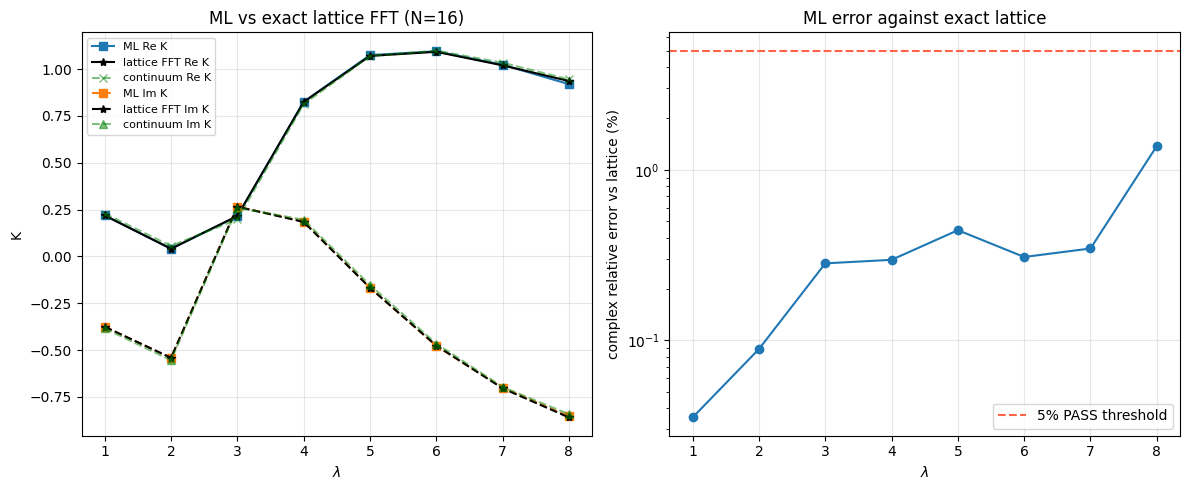

Saved summary plot: C:\xampp1\Quantum\runs\20260916_103537_MU_Loop_lambda1to8_N16\summary_ML_vs_lattice.png
PASS count: 8 / 8


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
lams = [row["lambda"] for row in all_rows]
ml = np.array([complex(row["K_ML_re"], row["K_ML_im"]) for row in all_rows])
lat = np.array([complex(row["K_lattice_re"], row["K_lattice_im"]) for row in all_rows])
cont = np.array([complex(row["K_continuum_re"], row["K_continuum_im"]) for row in all_rows])
err = [100.0 * row["complex_rel_err_vs_lattice"] for row in all_rows]

axes[0].plot(lams, ml.real, "s-", label="ML Re K")
axes[0].plot(lams, lat.real, "k*-", label="lattice FFT Re K")
axes[0].plot(lams, cont.real, "gx--", alpha=0.5, label="continuum Re K")
axes[0].plot(lams, ml.imag, "s--", label="ML Im K")
axes[0].plot(lams, lat.imag, "k*--", label="lattice FFT Im K")
axes[0].plot(lams, cont.imag, "g^--", alpha=0.5, label="continuum Im K")
axes[0].set_xlabel(r"$\lambda$")
axes[0].set_ylabel("K")
axes[0].set_title("ML vs exact lattice FFT (N=16)")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].semilogy(lams, np.maximum(err, 1e-6), "o-")
axes[1].axhline(5.0, color="tomato", ls="--", label="5% PASS threshold")
axes[1].set_xlabel(r"$\lambda$")
axes[1].set_ylabel("complex relative error vs lattice (%)")
axes[1].set_title("ML error against exact lattice")
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.tight_layout()
summary_plot = loop_dir / "summary_ML_vs_lattice.png"
fig.savefig(summary_plot, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved summary plot: {summary_plot.resolve()}")
print(f"PASS count: {sum(row['status']=='PASS' for row in all_rows)} / {len(all_rows)}")
